# Input Scaling: Why Standardizing Features Helps a Neural Network Train

Tabular datasets often mix features measured in wildly different units: a tumour's *area* in the thousands next to its *smoothness* of about 0.1. A neural network treats all inputs the same way, a weighted sum followed by a nonlinearity, so these **scales leak into the optimization**: features with big numbers dominate the first layer, gradients for different weights differ by orders of magnitude, and one learning rate cannot suit all of them.

```
 raw inputs                                   standardized inputs  x' = (x - mean) / std

   area        ~ 143 ... 2500                   area        ~ -2 ... 3
   smoothness  ~ 0.05 ... 0.16                  smoothness  ~ -2 ... 3
        \                                            \
         v   z = w1*area + w2*smoothness + b          v   z = w1*area' + w2*smoothness' + b

   d loss/d w1 is ~ 10^4 times larger than d loss/d w2        both gradients are on a comparable scale
   => long narrow valley, tiny usable learning rate           => rounder valley, one learning rate fits all
```

**What you will do**

1. Look at how different the feature scales are in three real datasets
2. Implement three scalers (standard, min-max, robust) from scratch and check them against scikit-learn
3. Train the **same network on raw and scaled inputs** and compare accuracy, speed and learning-rate sensitivity (3 seeds, with the learning rate tuned for *each* variant so the comparison is fair)
4. See **why** it helps: an optimization-geometry picture, feature dominance in the first layer, and activation saturation
5. Check whether an adaptive optimizer (Adam) makes scaling unnecessary
6. Test the **"how much does it matter?"** question across three datasets with very different scale mismatch
7. Avoid the classic pitfalls: forgetting to scale test data, and choosing a scaler that outliers can break

Everything runs on CPU in a few minutes.

## 0. Setup

In [1]:
import copy
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.datasets import load_breast_cancer, load_wine, load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

SEED = 0


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()
torch.set_num_threads(1)          # tiny networks run fastest single-threaded on CPU
print("torch", torch.__version__)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

LOADERS = {"breast_cancer": load_breast_cancer, "wine": load_wine, "digits": load_digits}


def load(name, seed=SEED):
    """Stratified 60 / 20 / 20 split. Raw, unscaled features: scaling is done later, on the training split only."""
    d = LOADERS[name]()
    X, y = d.data.astype(np.float64), d.target.astype(np.int64)
    X_tr, X_rest, y_tr, y_rest = train_test_split(X, y, test_size=0.4, stratify=y, random_state=seed)
    X_va, X_te, y_va, y_te = train_test_split(X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=seed)
    return dict(names=list(d.feature_names), X_tr=X_tr, y_tr=y_tr, X_va=X_va, y_va=y_va, X_te=X_te, y_te=y_te, n_classes=len(np.unique(y)))


DATA = {n: load(n) for n in LOADERS}
for n, d in DATA.items():
    print(f"{n:<14} features={d['X_tr'].shape[1]:>3}  classes={d['n_classes']}  train/val/test = {len(d['y_tr'])}/{len(d['y_va'])}/{len(d['y_te'])}")

torch 2.15.0+cu132
breast_cancer  features= 30  classes=2  train/val/test = 341/114/114
wine           features= 13  classes=3  train/val/test = 106/36/36
digits         features= 64  classes=10  train/val/test = 1078/359/360


## 1. How different are the scales?

For each dataset: the standard deviation of every feature, and the ratio of the largest to the smallest (ignoring constant features). The first plot shows all 30 breast-cancer features on a log axis.

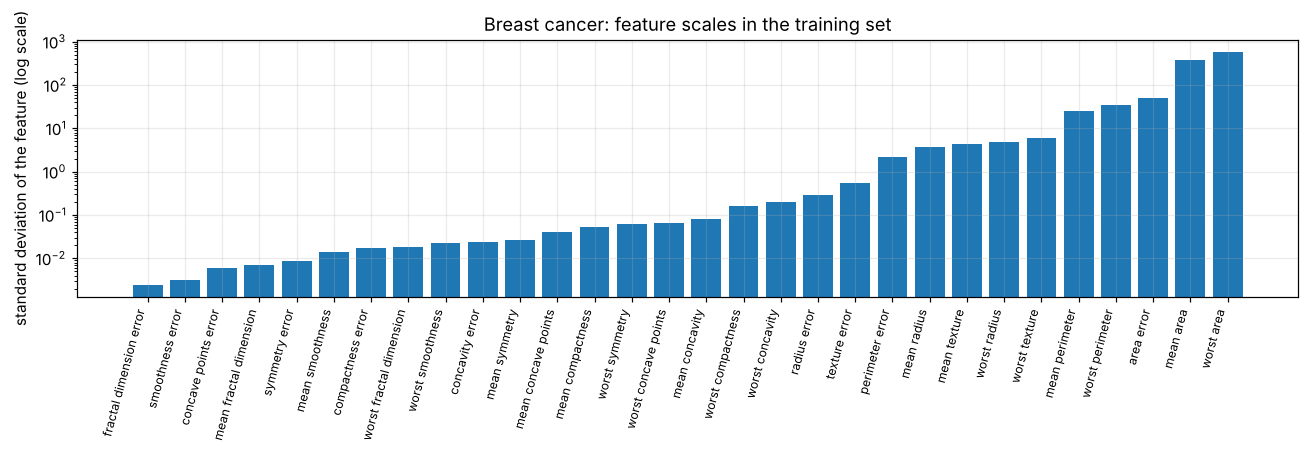

dataset         smallest std  largest std      ratio  features  variance share of the largest feature  (after standardizing)
breast_cancer         0.0024       591.08     244601        30                                 70.96%                  3.33%
wine                  0.1243       325.28       2617        13                                 99.80%                  7.69%
digits                0.0304         6.53        214        60                                  3.56%                  1.67%


In [2]:
bc = DATA["breast_cancer"]
sd = bc["X_tr"].std(0)
order = np.argsort(sd)
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.bar(range(len(sd)), sd[order], color="C0")
ax.set_yscale("log"); ax.set_xticks(range(len(sd))); ax.set_xticklabels([bc["names"][i] for i in order], rotation=75, ha="right", fontsize=8)
ax.set_ylabel("standard deviation of the feature (log scale)"); ax.set_title("Breast cancer: feature scales in the training set")
plt.tight_layout(); plt.show()

print(f"{'dataset':<14} {'smallest std':>13} {'largest std':>12} {'ratio':>10} {'features':>9} {'variance share of the largest feature':>38} {'(after standardizing)':>22}")
for n, d in DATA.items():
    X = d["X_tr"]; s = X.std(0); keep = s > 0
    var = X[:, keep].var(0)
    print(f"{n:<14} {s[keep].min():>13.4f} {s[keep].max():>12.2f} {s[keep].max() / s[keep].min():>10.0f} {keep.sum():>9d} {var.max() / var.sum():>38.2%} {1 / keep.sum():>22.2%}")

**What to notice.** The three datasets are very different. In **breast cancer** the feature scales span a factor of about 245,000 (from a standard deviation of 0.0024 to 591) and a single feature, *worst area*, carries 71% of the total variance; the three area/perimeter features together carry almost all of it. In **wine** the ratio is about 2,600 and one feature, *proline*, carries 99.8% of the variance. In **digits** the ratio is about 200, but it comes from rarely-active pixels: all pixels live in the same 0 to 16 range and the largest one carries only 3.6% of the variance. After standardizing, every feature carries an equal share (the last column).

So we have three situations: a few huge features that swamp the rest (wine, breast cancer), and features that already share a common unit (digits). We will see whether scaling matters in each of them.

## 2. Three scalers, from scratch

| Scaler | Formula | Properties |
|---|---|---|
| **Standardization** | `(x - mean) / std` | mean 0 and standard deviation 1 per feature; the usual default for neural networks |
| **Min-max** | `(x - min) / (max - min)` | maps the training range to [0, 1]; keeps the shape of the distribution; **sensitive to outliers** (they set the min and max) |
| **Robust** | `(x - median) / IQR` | uses the median and the interquartile range, so a few outliers barely matter |

The golden rule: **fit the scaler on the training split only**, then apply the *same* transform (the training mean, std, min, max...) to validation and test data. Computing statistics on all the data lets information about the test set leak into training.

scaler        max |difference| to scikit-learn, on train    on test
standard                                        0.00e+00   0.00e+00
minmax                                          2.22e-16   2.22e-16
robust                                          0.00e+00   0.00e+00


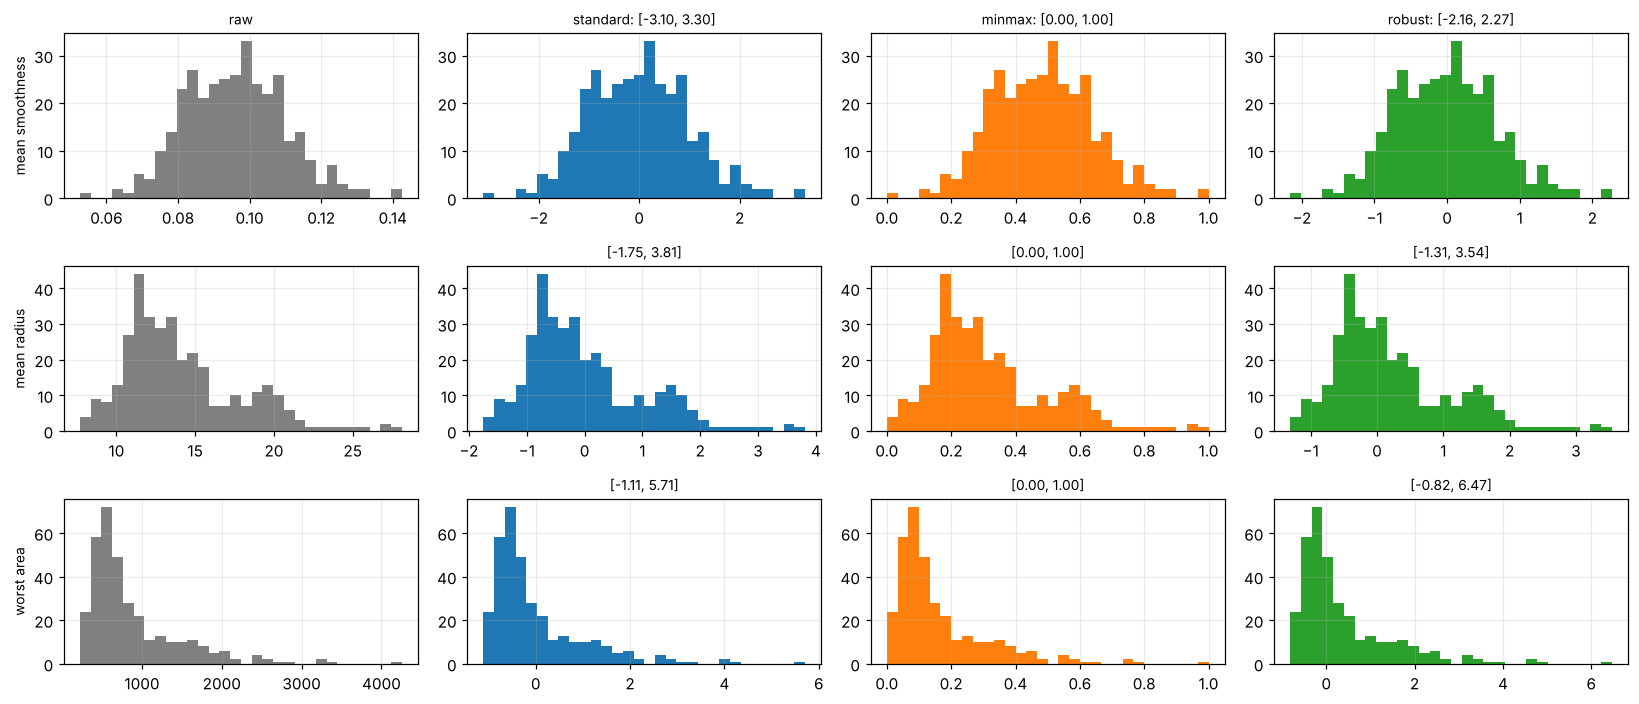

In [3]:
class StandardScaler_:
    def fit(self, X):
        self.mean, self.scale = X.mean(0), X.std(0)
        self.scale[self.scale == 0] = 1.0                 # constant feature: leave it alone
        return self
    def transform(self, X): return (X - self.mean) / self.scale


class MinMaxScaler_:
    def fit(self, X):
        self.min, self.range = X.min(0), X.max(0) - X.min(0)
        self.range[self.range == 0] = 1.0
        return self
    def transform(self, X): return (X - self.min) / self.range


class RobustScaler_:
    def fit(self, X):
        self.median = np.median(X, 0)
        self.iqr = np.percentile(X, 75, axis=0) - np.percentile(X, 25, axis=0)
        self.iqr[self.iqr == 0] = 1.0
        return self
    def transform(self, X): return (X - self.median) / self.iqr


SCALERS = {"standard": StandardScaler_, "minmax": MinMaxScaler_, "robust": RobustScaler_}

# check against scikit-learn: fit on train, transform train AND test
d = DATA["breast_cancer"]
print(f"{'scaler':<10} {'max |difference| to scikit-learn, on train':>45} {'on test':>10}")
for name, sk in (("standard", StandardScaler), ("minmax", MinMaxScaler), ("robust", RobustScaler)):
    mine, ref = SCALERS[name]().fit(d["X_tr"]), sk().fit(d["X_tr"])
    print(f"{name:<10} {np.abs(mine.transform(d['X_tr']) - ref.transform(d['X_tr'])).max():>45.2e} {np.abs(mine.transform(d['X_te']) - ref.transform(d['X_te'])).max():>10.2e}")

# what each scaler does to three very different features
feats = ["mean smoothness", "mean radius", "worst area"]
fig, axes = plt.subplots(len(feats), 4, figsize=(15, 6.5))
for r, f in enumerate(feats):
    j = d["names"].index(f)
    axes[r, 0].hist(d["X_tr"][:, j], bins=30, color="gray"); axes[r, 0].set_ylabel(f, fontsize=9)
    for c, (name, S) in enumerate(SCALERS.items(), start=1):
        v = S().fit(d["X_tr"]).transform(d["X_tr"])[:, j]
        axes[r, c].hist(v, bins=30, color=f"C{c - 1}")
        axes[r, c].set_title(f"{name}: [{v.min():.2f}, {v.max():.2f}]" if r == 0 else f"[{v.min():.2f}, {v.max():.2f}]", fontsize=9)
axes[0, 0].set_title("raw", fontsize=9)
plt.tight_layout(); plt.show()

**What to notice.** The from-scratch scalers match scikit-learn to machine precision, on the training data and on test data transformed with training statistics. The histograms show what each one does: all three keep the *shape* of the distribution (skewed features such as *worst area* stay skewed) and only change location and scale. Standardization gives mean 0 and standard deviation 1 (range -1.1 to 5.7 for *worst area*), min-max squeezes everything into [0, 1], and the robust scaler centers on the median and divides by the IQR (range -0.8 to 6.5). A feature with a long tail therefore has most of its mass in a narrow part of the min-max range, which sets up section 7b.

## 3. The network, the training loop, and a fair comparison

A small MLP (2 hidden layers of 64 ReLU units) trained with SGD with momentum 0.9, batch size 32, 100 epochs, **no early stopping** (we report the final epoch).

**A fair comparison needs a tuned learning rate for each variant.** Raw data is not just "worse": it simply needs a very different learning rate. If we fixed one learning rate we would be measuring how well that value suits each variant, not the effect of scaling. So for every variant we sweep the learning rate over 7 values (`1e-6` to `1`), 3 seeds each, pick the best by **validation** accuracy, and report **test** accuracy at that learning rate. The test set plays no part in any choice.

In [4]:
def make_data(name, scaler="none"):
    """Tensors for one dataset. The scaler (if any) is fitted on the training split only."""
    d = DATA[name]
    S = SCALERS[scaler]().fit(d["X_tr"]) if scaler != "none" else None
    f = (lambda X: S.transform(X)) if S else (lambda X: X)
    t = lambda X: torch.tensor(f(X), dtype=torch.float32)
    return dict(Xtr=t(d["X_tr"]), ytr=torch.tensor(d["y_tr"]), Xva=t(d["X_va"]), yva=torch.tensor(d["y_va"]),
                Xte=t(d["X_te"]), yte=torch.tensor(d["y_te"]), in_dim=d["X_tr"].shape[1], out_dim=d["n_classes"])


def make_mlp(D, activation="relu", hidden=64):
    act = {"relu": nn.ReLU, "tanh": nn.Tanh}[activation]
    return nn.Sequential(nn.Linear(D["in_dim"], hidden), act(), nn.Linear(hidden, hidden), act(), nn.Linear(hidden, D["out_dim"]))


@torch.no_grad()
def acc_loss(model, X, y):
    model.eval()
    out = model(X)
    return (out.argmax(1) == y).float().mean().item(), F.cross_entropy(out, y).item()


def fit(D, lr, opt="sgd", activation="relu", epochs=100, seed=0, batch_size=32, return_model=False):
    set_seed(seed)
    model = make_mlp(D, activation)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9) if opt == "sgd" else torch.optim.Adam(model.parameters(), lr=lr)
    g = torch.Generator().manual_seed(seed)
    h = dict(train_loss=[], val_acc=[], diverged=False)
    for _ in range(epochs):
        model.train()
        perm = torch.randperm(len(D["Xtr"]), generator=g)
        ep = []
        for i in range(0, len(perm), batch_size):
            idx = perm[i:i + batch_size]
            optimizer.zero_grad()
            loss = F.cross_entropy(model(D["Xtr"][idx]), D["ytr"][idx])
            if not torch.isfinite(loss):
                h["diverged"] = True
                break
            loss.backward(); optimizer.step(); ep.append(loss.item())
        if h["diverged"]:
            break
        h["train_loss"].append(float(np.mean(ep))); h["val_acc"].append(acc_loss(model, D["Xva"], D["yva"])[0])
    missing = epochs - len(h["val_acc"])
    if missing:                                                # pad a run that blew up (NaN loss): chance-level from then on
        h["train_loss"] += [np.nan] * missing; h["val_acc"] += [h["val_acc"][-1] if h["val_acc"] else 1.0 / D["out_dim"]] * missing
    va, vl = acc_loss(model, D["Xva"], D["yva"]); te, tl = acc_loss(model, D["Xte"], D["yte"])
    res = dict(val_acc=va, test_acc=te, hist=h)
    if return_model:
        res["model"] = model
    return res


SEEDS = range(3)
SGD_LRS = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]


def sweep(name, scaler, opt="sgd", lrs=SGD_LRS, activation="relu", epochs=100):
    D = make_data(name, scaler)
    return {lr: [fit(D, lr, opt, activation, epochs, seed=s) for s in SEEDS] for lr in lrs}


def best_lr(res):
    return max(res, key=lambda lr: np.mean([r["val_acc"] for r in res[lr]]))


t0 = time.time()
bc_res = {sc: sweep("breast_cancer", sc) for sc in ("none", "standard")}
print(f"breast cancer sweep done in {time.time() - t0:.0f}s")

print(f"\n{'':<10} | " + " ".join(f"{lr:>8.0e}" for lr in SGD_LRS) + "   <- mean validation accuracy for each learning rate")
for sc, label in (("none", "raw"), ("standard", "standardized")):
    print(f"{label:<12}| " + " ".join(f"{np.mean([r['val_acc'] for r in bc_res[sc][lr]]):>8.3f}" for lr in SGD_LRS))
print(f"{'diverged:':<12}")
for sc, label in (("none", "raw"), ("standard", "standardized")):
    print(f"  {label:<10}| " + " ".join(f"{sum(r['hist']['diverged'] for r in bc_res[sc][lr]):>8d}" for lr in SGD_LRS) + "   (runs out of 3 that hit NaN)")

breast cancer sweep done in 20s

           |    1e-06    1e-05    1e-04    1e-03    1e-02    1e-01    1e+00   <- mean validation accuracy for each learning rate
raw         |    0.939    0.921    0.921    0.792    0.632    0.635    0.544
standardized|    0.488    0.596    0.936    0.959    0.956    0.956    0.368
diverged:   
  raw       |        0        0        0        0        0        0        0   (runs out of 3 that hit NaN)
  standardized|        0        0        0        0        0        0        2   (runs out of 3 that hit NaN)


**What to notice.** The two variants work at *different* learning rates, three orders of magnitude apart. The **raw** network is only usable at tiny learning rates: it is best at the smallest value we tried (`1e-6`; the best raw result sits at the edge of the grid) and degrades steadily from `1e-3` upward, reaching 0.63 at `1e-2` (no run produces NaN, the network simply collapses into a poor solution). The **standardized** network is useless at `1e-6` and `1e-5` (too slow: 0.49 and 0.60) but works across roughly `1e-4` to `1e-1` (0.94 to 0.96), and only blows up at `1.0` (2 of 3 runs hit NaN). Standardizing does not just help; it shifts the best learning rate up by a factor of about 1,000 (from `1e-6` to `1e-3`) and opens a wide stable range around it.

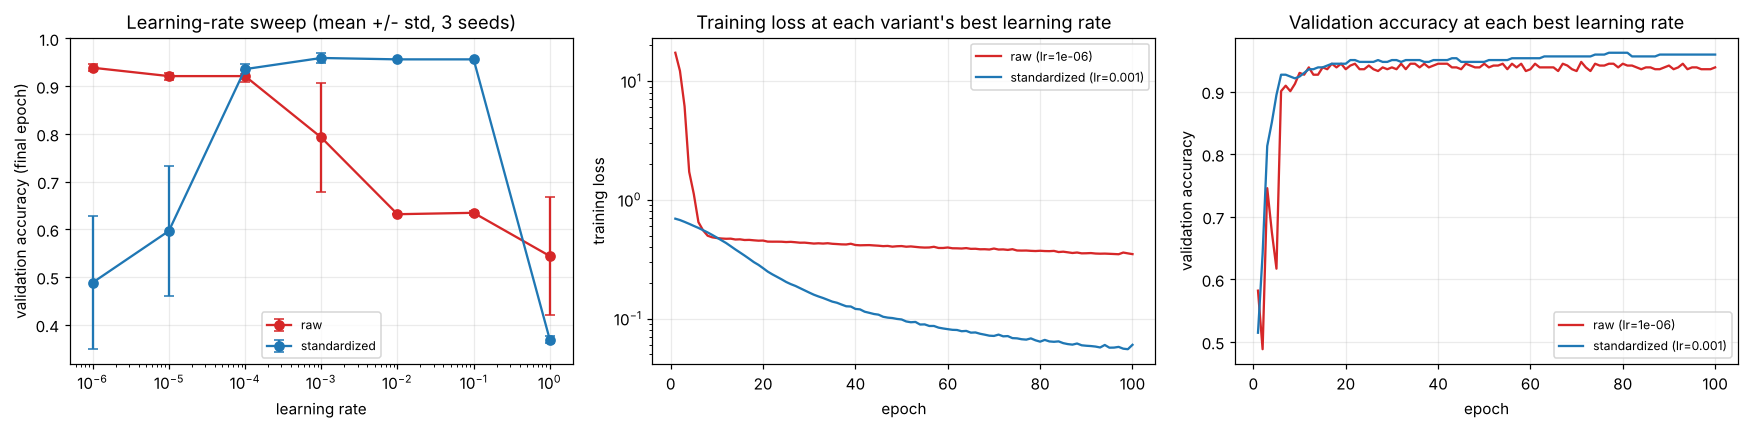

                best lr   val acc   test acc (mean +- std)   epochs to val acc >= 0.95
raw               1e-06     0.939          0.921 +- 0.026                       never
standardized      0.001     0.959          0.974 +- 0.000                          21


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
colors = {"none": "C3", "standard": "C0"}
labels = {"none": "raw", "standard": "standardized"}
for sc in ("none", "standard"):
    mu = [np.mean([r["val_acc"] for r in bc_res[sc][lr]]) for lr in SGD_LRS]
    sdv = [np.std([r["val_acc"] for r in bc_res[sc][lr]]) for lr in SGD_LRS]
    axes[0].errorbar(SGD_LRS, mu, yerr=sdv, marker="o", capsize=3, color=colors[sc], label=labels[sc])
    b = best_lr(bc_res[sc])
    axes[1].plot(np.arange(1, 101), np.mean([r["hist"]["train_loss"] for r in bc_res[sc][b]], 0), color=colors[sc], label=f"{labels[sc]} (lr={b:g})")
    axes[2].plot(np.arange(1, 101), np.mean([r["hist"]["val_acc"] for r in bc_res[sc][b]], 0), color=colors[sc], label=f"{labels[sc]} (lr={b:g})")
axes[0].set_xscale("log"); axes[0].set_xlabel("learning rate"); axes[0].set_ylabel("validation accuracy (final epoch)"); axes[0].set_title("Learning-rate sweep (mean +/- std, 3 seeds)")
axes[1].set_yscale("log"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("training loss"); axes[1].set_title("Training loss at each variant's best learning rate")
axes[2].set_xlabel("epoch"); axes[2].set_ylabel("validation accuracy"); axes[2].set_title("Validation accuracy at each best learning rate")
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'':<14} {'best lr':>8} {'val acc':>9} {'test acc (mean +- std)':>24} {'epochs to val acc >= 0.95':>27}")
for sc in ("none", "standard"):
    b = best_lr(bc_res[sc]); rs = bc_res[sc][b]
    m = np.mean([r["hist"]["val_acc"] for r in rs], 0); hit = np.where(m >= 0.95)[0]
    print(f"{labels[sc]:<14} {b:>8g} {np.mean([r['val_acc'] for r in rs]):>9.3f} {np.mean([r['test_acc'] for r in rs]):>14.3f} +- {np.std([r['test_acc'] for r in rs]):.3f} {(int(hit[0]) + 1 if len(hit) else 'never'):>27}")

**What to notice.** At each variant's own best learning rate, the standardized network trains much more effectively: validation accuracy 0.959 against 0.939, **test accuracy 0.974 against 0.921**, and it reaches 95% validation accuracy in 21 epochs while the raw network never gets there within 100 epochs. The loss curves show why: the raw network starts at a training loss of about 17 (it begins with enormous logits) and crawls down to only about 0.35 after 100 epochs at its tiny learning rate, while the standardized network starts at the chance-level 0.70 and falls to 0.06.

Keep the sample sizes in mind: the test set has only 114 examples, so a single example is about 0.9 points, and a 5-point gap is about 6 examples. The gap is consistent with the validation results and with the loss curves, but it is not a precisely measured number. Two further caveats: the raw network's best learning rate sits at the edge of our grid, and 100 epochs may under-train it (section 6a tests exactly that).

## 4. Why does scaling help?

### 4a. The geometry of the loss: long narrow valleys

Take the simplest case, **logistic regression with two features**, so the loss is a surface over two weights that we can draw. The features are centered, and feature 2 is simply 10 times larger than feature 1 (a *synthetic* example, so that the picture is clean); the standardized version is the same problem with the same optimal loss, only expressed in different units.

Gradient descent takes steps that are equal in all weight directions, and the safe step size is limited by the **steepest** direction (`lr < 2 / L`, where `L` is the largest curvature). In the raw problem the curvature along `w2` is about 100 times that along `w1` (the square of the scale ratio), so the safe learning rate is tiny for the flat direction, which therefore crawls.

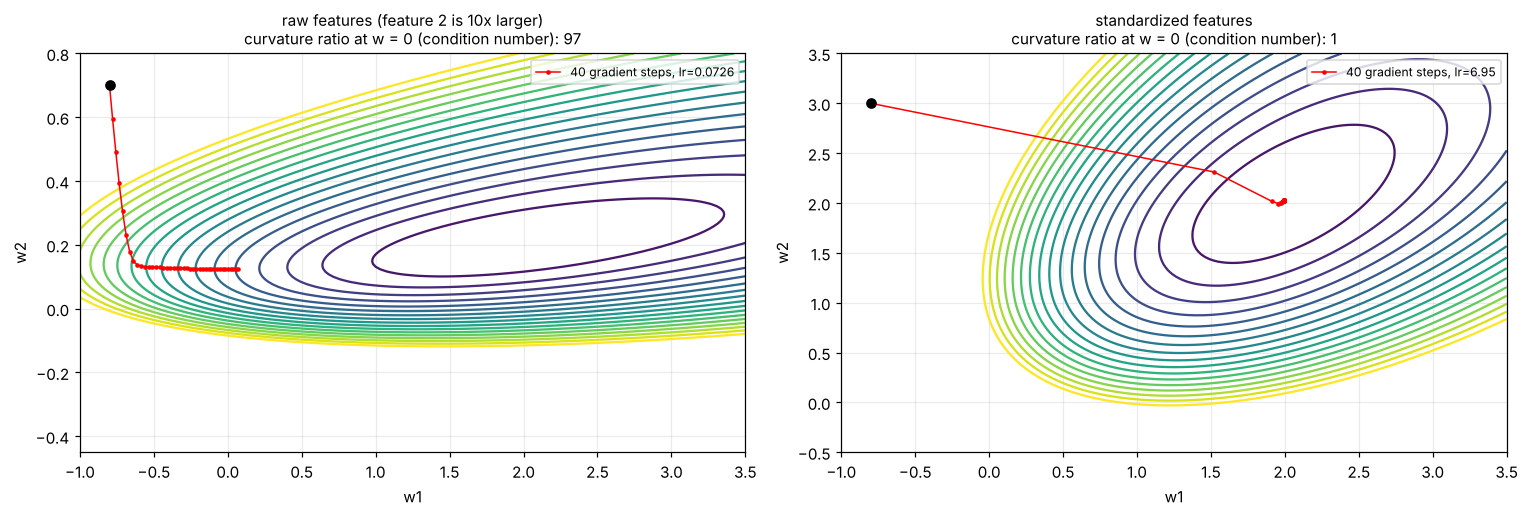

optimal loss (same for both parametrizations): 0.3739
  raw features (feature 2 is 10x larger)     condition number    97   loss after 40 steps 0.5464   gap to optimum 0.1726
  standardized features                      condition number     1   loss after 40 steps 0.3739   gap to optimum -0.0000


In [6]:
rng = np.random.default_rng(0)
n2, s2 = 4000, 10.0
Z = rng.standard_normal((n2, 2))
y2 = (rng.random(n2) < 1 / (1 + np.exp(-(2 * Z[:, 0] + 2 * Z[:, 1])))).astype(float)
X_raw2 = Z * np.array([1.0, s2])                          # feature 2 is 10x larger
X_std2 = (X_raw2 - X_raw2.mean(0)) / X_raw2.std(0)

sig = lambda z: 1 / (1 + np.exp(-z))
logloss = lambda w, X: np.mean(np.logaddexp(0, X @ w) - y2 * (X @ w))
grad_ = lambda w, X: X.T @ (sig(X @ w) - y2) / len(y2)

def gd_path(X, lr, steps, w0):
    w, path = np.array(w0, float), [np.array(w0, float)]
    for _ in range(steps):
        w = w - lr * grad_(w, X); path.append(w.copy())
    return np.array(path)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
info = {}
for ax, (title, X, win, w0) in zip(axes, (("raw features (feature 2 is 10x larger)", X_raw2, (-1.0, 3.5, -0.45, 0.8), (-0.8, 0.7)),
                                           ("standardized features", X_std2, (-1.0, 3.5, -0.5, 3.5), (-0.8, 3.0)))):
    L = 0.25 * np.linalg.eigvalsh(X.T @ X / len(X)).max()      # smoothness bound of the logistic loss
    lam = np.linalg.eigvalsh(0.25 * X.T @ X / len(X))
    lr = 1.8 / L                                               # close to the largest stable step size
    path = gd_path(X, lr, 40, w0)
    gx, gy = np.meshgrid(np.linspace(win[0], win[1], 160), np.linspace(win[2], win[3], 160))
    zz = np.array([[logloss(np.array([a, b]), X) for a, b in zip(r1, r2)] for r1, r2 in zip(gx, gy)])
    ax.contour(gx, gy, zz, levels=np.linspace(zz.min(), np.percentile(zz, 60), 18), cmap="viridis")
    ax.plot(path[:, 0], path[:, 1], "r.-", ms=4, lw=1, label=f"40 gradient steps, lr={lr:.3g}")
    ax.plot(*path[0], "ko"); ax.set_xlabel("w1"); ax.set_ylabel("w2"); ax.set_title(f"{title}\ncurvature ratio at w = 0 (condition number): {lam.max() / lam.min():.0f}", fontsize=10)
    ax.set_xlim(win[0], win[1]); ax.set_ylim(win[2], win[3]); ax.legend(fontsize=8, loc="upper right")
    info[title] = (lam.max() / lam.min(), logloss(path[-1], X))
plt.tight_layout(); plt.show()

w_star = minimize(lambda w: logloss(w, X_std2), np.zeros(2)).x
opt_loss = logloss(w_star, X_std2)
print(f"optimal loss (same for both parametrizations): {opt_loss:.4f}")
for k, (cn, l) in info.items():
    print(f"  {k:<42} condition number {cn:>5.0f}   loss after 40 steps {l:.4f}   gap to optimum {l - opt_loss:.4f}")

**What to notice.** Both panels are the same problem with the same optimal loss (0.374); only the units of feature 2 differ. In the raw problem the loss is **about 100 times more curved along `w2` than along `w1`** (curvature ratio 97), giving a long narrow valley. The safe step size is set by the steep direction, so the path drops down the steep wall quickly and then **crawls along the valley floor**: after 40 steps the loss is still 0.17 above the optimum. In the standardized problem the bowl is nearly round at the start (curvature ratio 1 at `w = 0`; away from the origin the contours tilt, because logistic curvature depends on the predicted probabilities), and the same step budget lands on the optimum: the loss is within 0.001 of it after only 2 steps (the raw problem has not got that close even after 200 steps). In a real network the same effect applies to every layer at once, with 30 features instead of 2 and ratios far above 10.

### 4b. In the first layer, large-scale features dominate

A first-layer unit computes `z = sum_j w_j x_j + b`. With weights drawn from the same distribution for every input, the variance of `z` contributed by feature `j` is proportional to the **variance of that feature**. Below: each breast-cancer feature's share of the total first-layer pre-activation variance at initialization, raw vs standardized (the shares are the same for every unit, in expectation).

We also look at the network's state **at initialization**: the loss it starts with, and for a `tanh` version the fraction of first-layer units that start **saturated** (`|tanh| > 0.99`, where the gradient is essentially zero).

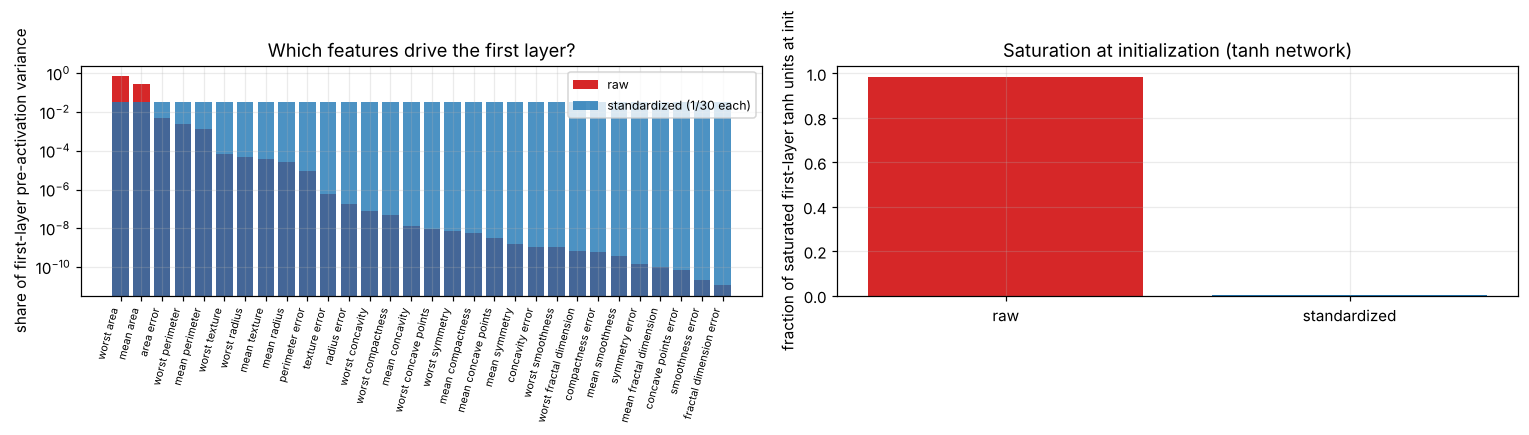

largest single-feature share of first-layer variance, raw: 70.9618%  (worst area);  top 3 together: 99.6081%

at initialization   initial loss (ReLU)   saturated tanh units  |grad| layer 1  |grad| layer 3
raw                              18.678                  98.4%        143.0506        209.6607
standardized                      0.696                   0.3%          0.2023          0.2800


In [7]:
Xr = DATA["breast_cancer"]["X_tr"]
share_raw = Xr.var(0) / Xr.var(0).sum()
share_std = np.full(Xr.shape[1], 1.0 / Xr.shape[1])
names = DATA["breast_cancer"]["names"]
idx = np.argsort(-share_raw)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].bar(range(len(idx)), share_raw[idx], color="C3", label="raw"); axes[0].bar(range(len(idx)), share_std[idx], color="C0", alpha=0.8, label="standardized (1/30 each)")
axes[0].set_xticks(range(len(idx))); axes[0].set_xticklabels([names[i] for i in idx], rotation=75, ha="right", fontsize=7)
axes[0].set_yscale("log"); axes[0].set_ylabel("share of first-layer pre-activation variance"); axes[0].set_title("Which features drive the first layer?"); axes[0].legend(fontsize=8)

rows = []
for sc, label in (("none", "raw"), ("standard", "standardized")):
    D = make_data("breast_cancer", sc)
    losses, sat, g1, g3 = [], [], [], []
    for s in range(10):
        set_seed(s)
        m = make_mlp(D, "relu")
        loss = F.cross_entropy(m(D["Xtr"]), D["ytr"]); loss.backward()
        losses.append(loss.item()); g1.append(m[0].weight.grad.norm().item()); g3.append(m[4].weight.grad.norm().item())
        set_seed(s)
        mt = make_mlp(D, "tanh")
        sat.append((torch.tanh(mt[0](D["Xtr"])).abs() > 0.99).float().mean().item())
    rows.append((label, np.mean(losses), np.mean(sat), np.mean(g1), np.mean(g3)))
axes[1].bar([r[0] for r in rows], [r[2] for r in rows], color=["C3", "C0"]); axes[1].set_ylabel("fraction of saturated first-layer tanh units at init"); axes[1].set_title("Saturation at initialization (tanh network)")
plt.tight_layout(); plt.show()

print(f"largest single-feature share of first-layer variance, raw: {share_raw.max():.4%}  ({names[idx[0]]});  top 3 together: {np.sort(share_raw)[-3:].sum():.4%}")
print(f"\n{'at initialization':<18} {'initial loss (ReLU)':>20} {'saturated tanh units':>22} {'|grad| layer 1':>15} {'|grad| layer 3':>15}")
for r in rows:
    print(f"{r[0]:<18} {r[1]:>20.3f} {r[2]:>22.1%} {r[3]:>15.4f} {r[4]:>15.4f}")

**What to notice.** At initialization, a single raw feature (*worst area*) accounts for 71% of the first-layer variance and the top three for 99.6%; the other 27 features share the remaining 0.4%, so the network is practically blind to them until the weights adapt, and the weights on the big features have to be driven to tiny values just to get sensible outputs. The consequences at initialization are dramatic:

- the starting loss of the ReLU network is **18.7 against 0.70** (chance level is 0.693 for two classes)
- **98.4% of the first-layer `tanh` units are saturated** (`|tanh| > 0.99`) against 0.3%, and saturated units pass almost no gradient
- the gradient norms are about **143 and 210 in layers 1 and 3 against 0.20 and 0.28**, roughly 700 times larger; with gradients that size, any learning rate above about `1e-4` produces updates large enough to wreck the weights, which is exactly the learning-rate ceiling we found in section 3

(For a `tanh` or sigmoid network, saturation is an additional reason raw data is hard to train; ReLU networks suffer from the first two effects instead.)

## 5. Does an adaptive optimizer make scaling unnecessary?

Adam rescales each weight's update by a running estimate of its gradient magnitude, so it partly corrects for different gradient scales by itself. Does that remove the need to scale inputs? We repeat the learning-rate sweep with Adam (5 values from `1e-4` to `1`, same 3 seeds and the same selection rule) and put it next to SGD.

done in 21s


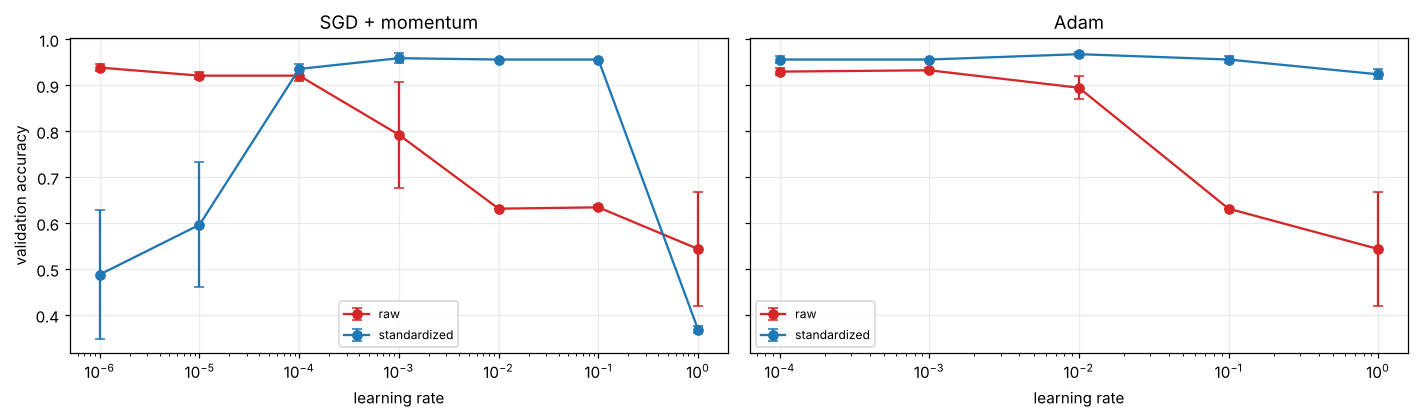

optimizer  inputs         best lr  val acc  test acc   # learning rates within 0.02 of best
SGD        raw              1e-06    0.939     0.921   3 of 7
SGD        standardized     0.001    0.959     0.974   3 of 7
Adam       raw              0.001    0.933     0.947   2 of 5
Adam       standardized      0.01    0.968     0.971   4 of 5


In [8]:
ADAM_LRS = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]
t0 = time.time()
bc_adam = {sc: sweep("breast_cancer", sc, opt="adam", lrs=ADAM_LRS) for sc in ("none", "standard")}
print(f"done in {time.time() - t0:.0f}s")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9), sharey=True)
for ax, (title, res, lrs) in zip(axes, (("SGD + momentum", bc_res, SGD_LRS), ("Adam", bc_adam, ADAM_LRS))):
    for sc in ("none", "standard"):
        ax.errorbar(lrs, [np.mean([r["val_acc"] for r in res[sc][lr]]) for lr in lrs], yerr=[np.std([r["val_acc"] for r in res[sc][lr]]) for lr in lrs],
                    marker="o", capsize=3, color=colors[sc], label=labels[sc])
    ax.set_xscale("log"); ax.set_xlabel("learning rate"); ax.set_title(title); ax.legend(fontsize=8)
axes[0].set_ylabel("validation accuracy")
plt.tight_layout(); plt.show()

def summary_row(res):
    b = best_lr(res); rs = res[b]
    good = sum(np.mean([r["val_acc"] for r in res[lr]]) >= np.mean([r["val_acc"] for r in rs]) - 0.02 for lr in res)
    return b, np.mean([r["val_acc"] for r in rs]), np.mean([r["test_acc"] for r in rs]), good

print(f"{'optimizer':<10} {'inputs':<13} {'best lr':>8} {'val acc':>8} {'test acc':>9} {'# learning rates within 0.02 of best':>38}")
for opt, res, lrs in (("SGD", bc_res, SGD_LRS), ("Adam", bc_adam, ADAM_LRS)):
    for sc in ("none", "standard"):
        b, va, te, good = summary_row(res[sc])
        print(f"{opt:<10} {labels[sc]:<13} {b:>8g} {va:>8.3f} {te:>9.3f} {good:>3d} of {len(lrs)}")

**What to notice.** Adam **helps raw inputs a lot**: its best raw result is 0.947 test accuracy at `lr = 1e-3`, against 0.921 with SGD at `1e-6`, because it divides each update by its recent gradient magnitude and so partly absorbs the huge gradients. But it does **not** remove the benefit of scaling. Standardized inputs with Adam still give the best result (0.968 validation, 0.971 test against 0.933 and 0.947), and the learning-rate range that works is wider: 4 of the 5 values are within 0.02 of the best for standardized inputs against 2 of 5 for raw, and raw Adam collapses at `lr >= 0.1` (0.63 and 0.54) while standardized Adam stays above 0.92 even at `lr = 1`. Scaling and adaptive optimizers are complementary rather than substitutes.

## 6. How much does it matter? Three datasets

The effect of scaling should depend on **how mismatched the feature scales are** (section 1). We repeat the tuned-learning-rate comparison (SGD, 7 learning rates, 3 seeds, 100 epochs) on the wine data (scale ratio about 2,500) and on handwritten digits (all pixels live in 0 to 16, ratio about 280), next to the breast-cancer result.

wine done in 7s


digits done in 71s


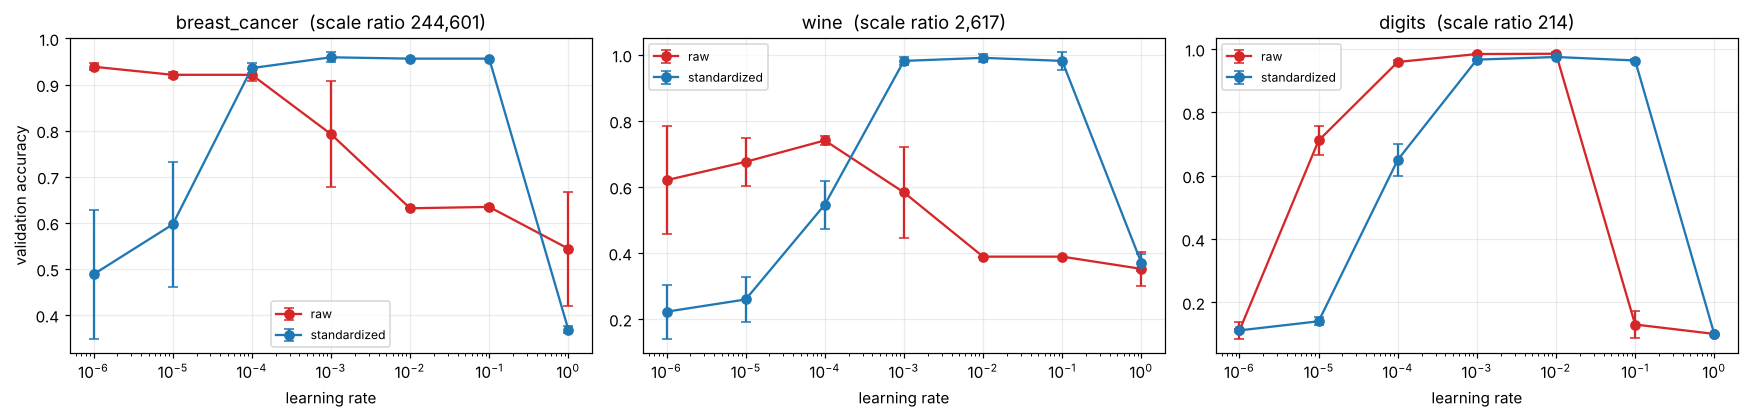

dataset        scale ratio | inputs         best lr  val acc   test acc (mean +- std)  good lrs
breast_cancer      244,601 | raw              1e-06    0.939          0.921 +- 0.026      3/7
breast_cancer      244,601 | standardized     0.001    0.959          0.974 +- 0.000      3/7
wine                 2,617 | raw             0.0001    0.741          0.602 +- 0.013      1/7
wine                 2,617 | standardized      0.01    0.991          0.972 +- 0.023      3/7
digits                 214 | raw               0.01    0.985          0.976 +- 0.003      2/7
digits                 214 | standardized      0.01    0.975          0.969 +- 0.003      3/7


In [9]:
t0 = time.time()
all_res = {"breast_cancer": bc_res}
for name in ("wine", "digits"):
    all_res[name] = {sc: sweep(name, sc) for sc in ("none", "standard")}
    print(f"{name} done in {time.time() - t0:.0f}s")

ratio = {}
for n, d in DATA.items():
    s = d["X_tr"].std(0); s = s[s > 0]; ratio[n] = s.max() / s.min()

fig, axes = plt.subplots(1, 3, figsize=(16, 3.9))
for ax, n in zip(axes, all_res):
    for sc in ("none", "standard"):
        res = all_res[n][sc]
        ax.errorbar(SGD_LRS, [np.mean([r["val_acc"] for r in res[lr]]) for lr in SGD_LRS], yerr=[np.std([r["val_acc"] for r in res[lr]]) for lr in SGD_LRS],
                    marker="o", capsize=3, color=colors[sc], label=labels[sc])
    ax.set_xscale("log"); ax.set_xlabel("learning rate"); ax.set_title(f"{n}  (scale ratio {ratio[n]:,.0f})"); ax.legend(fontsize=8)
axes[0].set_ylabel("validation accuracy")
plt.tight_layout(); plt.show()

print(f"{'dataset':<14} {'scale ratio':>11} | {'inputs':<13} {'best lr':>8} {'val acc':>8} {'test acc (mean +- std)':>24} {'good lrs':>9}")
for n in all_res:
    for sc in ("none", "standard"):
        res = all_res[n][sc]; b, va, te, good = summary_row(res)
        sdv = np.std([r["test_acc"] for r in res[b]])
        print(f"{n:<14} {ratio[n]:>11,.0f} | {labels[sc]:<13} {b:>8g} {va:>8.3f} {te:>14.3f} +- {sdv:.3f} {good:>6d}/7")

**What to notice.** The benefit of scaling depends heavily on the data.

- **Breast cancer** (ratio about 245,000; one feature carries 71% of the variance): test accuracy 0.921 raw against 0.974 standardized, +5 points.
- **Wine** (ratio about 2,600; *proline* carries 99.8% of the variance): **0.602 against 0.972**, +37 points. Raw wine does not get above 0.74 validation accuracy at any learning rate we tried, and only one of the 7 learning rates is within 0.02 of its best.
- **Digits** (all pixels in the same range): **no benefit**. Raw is, if anything, slightly better (0.976 against 0.969 test, 0.985 against 0.975 validation, a difference of about two examples out of 360 and within what 3 seeds can resolve), and the learning-rate ranges are similar, only shifted by about one decade. Standardizing here means dividing rarely-active pixels by a small standard deviation, which can inflate noise, so it is not a free improvement.

The pattern is *not* "bigger scale ratio, bigger gain" (wine gains more than breast cancer, which has the larger ratio). What matters is **whether a few large-valued features dominate the others in the first layer** (99.8% of the variance in wine, 71% in breast cancer, 3.6% in digits), and whether the small features carry information the network needs. When the features already share a unit, scaling is a minor decision.

### 6a. Is raw just slow? Give it 10 times more epochs

The comparison above gives every variant the same 100-epoch budget. Raw inputs need a tiny learning rate, which makes training slow, so one fair objection is that the raw network is merely *under-trained*. We re-train the raw networks at their best learning rate for **1000 epochs** (3 seeds) and see how far they get.

In [10]:
t0 = time.time()
long_runs = {}
for n in ("breast_cancer", "wine"):
    b = best_lr(all_res[n]["none"])
    D = make_data(n, "none")
    long_runs[n] = (b, [fit(D, b, epochs=1000, seed=s) for s in SEEDS])
print(f"done in {time.time() - t0:.0f}s\n")
print(f"{'dataset':<14} {'raw lr':>8} | {'raw, 100 epochs':>16} {'raw, 1000 epochs':>17} | {'standardized, 100 epochs':>25}")
for n in long_runs:
    b, rs = long_runs[n]
    r100 = all_res[n]["none"][b]; s_b = best_lr(all_res[n]["standard"]); s100 = all_res[n]["standard"][s_b]
    print(f"{n:<14} {b:>8g} | {np.mean([r['test_acc'] for r in r100]):>16.3f} {np.mean([r['test_acc'] for r in rs]):>17.3f} | {np.mean([r['test_acc'] for r in s100]):>25.3f}   (test accuracy)")
    print(f"{'':<14} {'':>8} | final training loss: raw/100 ep {np.mean([r['hist']['train_loss'][-1] for r in r100]):.3f}, raw/1000 ep {np.mean([r['hist']['train_loss'][-1] for r in rs]):.3f}, standardized/100 ep {np.mean([r['hist']['train_loss'][-1] for r in s100]):.3f}")

done in 20s

dataset          raw lr |  raw, 100 epochs  raw, 1000 epochs |  standardized, 100 epochs
breast_cancer     1e-06 |            0.921             0.936 |                     0.974   (test accuracy)
                        | final training loss: raw/100 ep 0.349, raw/1000 ep 0.221, standardized/100 ep 0.060
wine             0.0001 |            0.602             0.741 |                     0.972   (test accuracy)
                        | final training loss: raw/100 ep 0.601, raw/1000 ep 0.428, standardized/100 ep 0.004


**What to notice.** Part of the raw network's deficit is indeed under-training: with 10 times more epochs the raw wine network improves from 0.602 to 0.741 test accuracy and its training loss from 0.60 to 0.43, and raw breast cancer from 0.921 to 0.936 (training loss 0.35 to 0.22). But neither catches up with the standardized network trained for only 100 epochs (0.972 and 0.974, training losses 0.004 and 0.060). Scaling is worth roughly an order of magnitude in training budget here, plus the learning-rate tuning you save. One caveat: the raw learning rate was picked on the 100-epoch grid, and a finer search might narrow the gap somewhat further.

## 7. Pitfalls

### 7a. Forgetting to scale at test time

The network learns to expect standardized inputs. If at inference you feed it raw features (a pipeline bug that is easy to make), the predictions are meaningless. We train on standardized breast-cancer data and evaluate the same model on the test set three ways: correctly transformed with the *training* statistics, left raw, and wrongly standardized with the *test* set's own statistics (a "leak" of a different kind, which is harmless here but fragile for a single example, since one sample has no meaningful mean and std).

In [11]:
D_std = make_data("breast_cancer", "standard")
b_std = best_lr(bc_res["standard"])
accs = {"correct: training mean/std": [], "wrong: raw test features": [], "wrong: test set's own mean/std": []}
d = DATA["breast_cancer"]
for s in SEEDS:
    m = fit(D_std, b_std, seed=s, return_model=True)["model"]
    accs["correct: training mean/std"].append(acc_loss(m, D_std["Xte"], D_std["yte"])[0])
    accs["wrong: raw test features"].append(acc_loss(m, torch.tensor(d["X_te"], dtype=torch.float32), D_std["yte"])[0])
    Xt_own = torch.tensor(StandardScaler().fit_transform(d["X_te"]), dtype=torch.float32)
    accs["wrong: test set's own mean/std"].append(acc_loss(m, Xt_own, D_std["yte"])[0])
print(f"majority-class accuracy on the test set: {max(np.bincount(d['y_te'])) / len(d['y_te']):.3f}\n")
for k, v in accs.items():
    print(f"{k:<34} test accuracy {np.mean(v):.3f} +- {np.std(v):.3f}")

majority-class accuracy on the test set: 0.623

correct: training mean/std         test accuracy 0.974 +- 0.000
wrong: raw test features           test accuracy 0.377 +- 0.000
wrong: test set's own mean/std     test accuracy 0.980 +- 0.004


**What to notice.** Feeding raw features to the network trained on standardized data gives **0.377 test accuracy, worse than always predicting the majority class (0.623)**: the network predicts the same wrong class for essentially everything. This is a silent failure: nothing crashes, the outputs just become nonsense, and it is a very common production bug. The cure is to treat the scaler as part of the model: save the training mean and standard deviation with the weights and apply them at inference.

Standardizing the test set with *its own* mean and standard deviation scores 0.980 here, about the same as the correct method (0.974), so on a large, well-behaved test set it is harmless. It is still the wrong thing to do: it is impossible for a single example (one sample has no standard deviation), it changes with the composition of each batch, and it hides distribution shift that you would want to detect.

### 7b. Choosing a scaler: outliers

Min-max scaling uses the extreme values, so a handful of outliers can squeeze everything else into a tiny interval. Standardization is affected less (the standard deviation grows with the outliers), and robust scaling (median and IQR) should hardly be affected. We simulate **a few records entered in the wrong units**: in the training set only, we multiply *all* features of a few rows by 30 (5 rows) or by 100 (10 rows). Validation and test data stay clean. We compare the three scalers with the learning rate tuned for each (5 values, SGD, 5 seeds).

Where does the bulk of the CLEAN validation values of 'mean area' land after scaling? (width of their central 50%)
                  standard      minmax      robust
clean               0.8655      0.1382      0.8601
5 rows x30          0.1425      0.0090      0.8173
10 rows x100        0.0187      0.0013      0.7835



trained in 109s


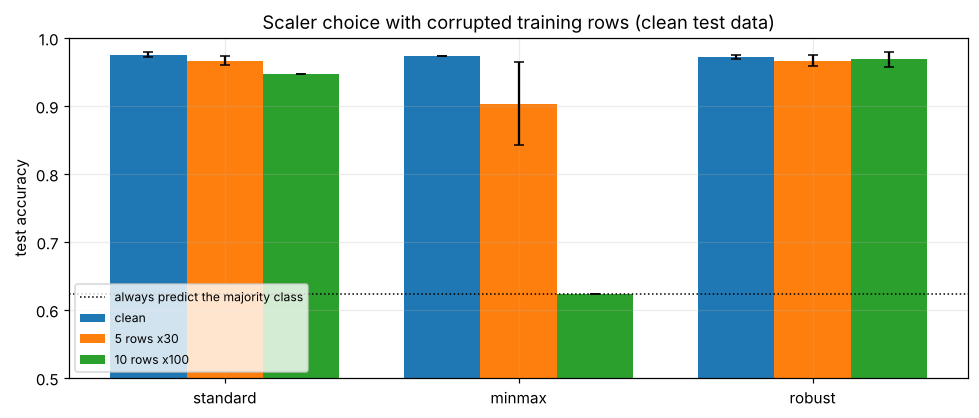


training data  scaler     best lr    test acc (mean +- std, 5 seeds)
clean          standard     0.001                0.975 +- 0.004
clean          minmax        0.01                0.974 +- 0.000
clean          robust       0.003                0.972 +- 0.004
5 rows x30     standard     0.003                0.967 +- 0.007
5 rows x30     minmax        0.03                0.904 +- 0.061
5 rows x30     robust       0.003                0.967 +- 0.009
10 rows x100   standard      0.01                0.947 +- 0.000
10 rows x100   minmax       0.001                0.623 +- 0.000
10 rows x100   robust        0.01                0.968 +- 0.011


In [12]:
CONDITIONS = {"clean": (0, 1.0), "5 rows x30": (5, 30.0), "10 rows x100": (10, 100.0)}
SEEDS5 = range(5)


def outlier_data(scaler, k, mult):
    d = DATA["breast_cancer"]
    Xtr = d["X_tr"].copy()
    if k:
        rows = np.random.default_rng(0).choice(len(Xtr), k, replace=False)
        Xtr[rows, :] *= mult                              # a few training records in the wrong units, ALL features
    S = SCALERS[scaler]().fit(Xtr)
    t = lambda X: torch.tensor(S.transform(X), dtype=torch.float32)
    D = dict(Xtr=t(Xtr), ytr=torch.tensor(d["y_tr"]), Xva=t(d["X_va"]), yva=torch.tensor(d["y_va"]), Xte=t(d["X_te"]), yte=torch.tensor(d["y_te"]),
             in_dim=Xtr.shape[1], out_dim=2)
    return D, S


j = DATA["breast_cancer"]["names"].index("mean area")
print("Where does the bulk of the CLEAN validation values of 'mean area' land after scaling? (width of their central 50%)")
print(f"{'':<14}" + "".join(f"{sc:>12}" for sc in SCALERS))
for cname, (k, mult) in CONDITIONS.items():
    row = []
    for sc in SCALERS:
        _, S = outlier_data(sc, k, mult)
        v = S.transform(DATA["breast_cancer"]["X_va"])[:, j]
        row.append(np.percentile(v, 75) - np.percentile(v, 25))
    print(f"{cname:<14}" + "".join(f"{r:>12.4f}" for r in row))

LRS4 = [1e-3, 3e-3, 1e-2, 3e-2, 1e-1]
t0 = time.time()
out_res = {}
for cname, (k, mult) in CONDITIONS.items():
    for sc in SCALERS:
        D, _ = outlier_data(sc, k, mult)
        out_res[(cname, sc)] = {lr: [fit(D, lr, seed=s) for s in SEEDS5] for lr in LRS4}
print(f"\ntrained in {time.time() - t0:.0f}s")

fig, ax = plt.subplots(figsize=(9, 3.9))
w = 0.26
for k_, cname in enumerate(CONDITIONS):
    mu, sdv = [], []
    for sc in SCALERS:
        res = out_res[(cname, sc)]; b = best_lr(res)
        mu.append(np.mean([r["test_acc"] for r in res[b]])); sdv.append(np.std([r["test_acc"] for r in res[b]]))
    ax.bar(np.arange(3) + (k_ - 1) * w, mu, w, yerr=sdv, capsize=3, label=cname)
ax.axhline(max(np.bincount(DATA["breast_cancer"]["y_te"])) / len(DATA["breast_cancer"]["y_te"]), color="k", ls=":", lw=1, label="always predict the majority class")
ax.set_xticks(range(3)); ax.set_xticklabels(list(SCALERS)); ax.set_ylim(0.5, 1.0); ax.set_ylabel("test accuracy"); ax.legend(fontsize=8, loc="lower left"); ax.set_title("Scaler choice with corrupted training rows (clean test data)")
plt.tight_layout(); plt.show()
print(f"\n{'training data':<14} {'scaler':<9} {'best lr':>8} {'test acc (mean +- std, 5 seeds)':>34}")
for cname in CONDITIONS:
    for sc in SCALERS:
        res = out_res[(cname, sc)]; b = best_lr(res)
        print(f"{cname:<14} {sc:<9} {b:>8g} {np.mean([r['test_acc'] for r in res[b]]):>20.3f} +- {np.std([r['test_acc'] for r in res[b]]):.3f}")

**What to notice.** On **clean** data the three scalers are equivalent (0.972 to 0.975 test accuracy), so the choice does not matter much. With corrupted rows they separate:

- the width of the central half of the (clean) *mean area* values after scaling drops from 0.87 to 0.14 to 0.019 for standardization as the corruption grows, from 0.14 to 0.009 to 0.001 for min-max, and barely moves for the robust scaler (0.86, 0.82, 0.78)
- **min-max collapses**: 0.904 (with a large spread over seeds, 0.06) with 5 bad rows, and **0.623 with 10 bad rows, which is exactly the majority-class accuracy**: the clean data is squeezed into an interval about 0.001 wide and the network cannot learn from it with the learning rates we tried (up to 0.1; larger ones might recover some accuracy)
- **standardization degrades gracefully** (0.967, then 0.947)
- **robust scaling is unaffected** (0.967, 0.968)

This is a stress test of my own design, so it favors the robust scaler by construction: real outliers are rarely this uniform, and the better fix is usually to find and correct the bad records. Still, it shows why a scaler based on the min and max is the most fragile, and why robust scaling is a good default for messy data. Min-max remains natural for features that are bounded by design, such as pixel intensities.

## 8. Summary

**What scaling does.** It puts all inputs on a comparable scale (usually mean 0, standard deviation 1), using statistics computed on the training data only.

**What this notebook found**

1. **Fair comparison (section 3).** With the learning rate tuned separately for each variant, standardized breast-cancer inputs give 0.974 test accuracy against 0.921 for raw, reach 95% validation accuracy in 21 epochs (raw never does in 100), and work over a learning-rate range of about three decades (`1e-4` to `1e-1`) where raw works only below about `1e-4`.
2. **Why (section 4).** Raw features create a badly conditioned problem (curvature ratio 97 in the 2-feature picture), let a few large features dominate the first layer (71% of its variance from one feature, 99.6% from three), and make the network start with a loss of 18.7, 98% saturated `tanh` units and gradients about 700 times larger.
3. **Adam helps but does not replace scaling (section 5).** Raw inputs improve from 0.921 to 0.947 test accuracy with Adam, still below standardized inputs (0.971) with a narrower usable learning-rate range.
4. **It depends on the data (section 6).** +5 points on breast cancer, +37 on wine, about 0 on digits. The deciding factor is whether a few large-valued features dominate, not simply the size of the scale ratio. Raw is partly just slow (section 6a), but 10 times more epochs does not close the gap.
5. **Pitfalls (section 7).** Forgetting to scale at inference gave 0.377, below the majority-class baseline. Min-max scaling is the most fragile with outliers (0.623 with 10 bad rows), standardization degrades gracefully, robust scaling is stable.

**Practical notes**

- **Fit on the training split only**, then apply the same transform to validation, test and production data; ship the scaler together with the model.
- Standardization is the default for tabular data and neural networks. Use robust scaling when outliers are likely, and min-max for features that are naturally bounded. Check for corrupted records first.
- Images are usually divided by 255 and sometimes standardized per channel with training-set statistics; digits showed that when inputs already share a unit, scaling is a minor choice.
- Scaling inputs is not the same as normalization layers inside the network (BatchNorm, LayerNorm), which address a related problem for hidden activations. Neither replaces the other as a cheap first step for tabular inputs, but we did not test the combination here.
- Not tested here: heavy-tailed features (consider a log transform first), and scaling the **targets** in regression problems, which is just as important there.

**Try it yourself**

1. Extend the SGD learning-rate grid downward (`1e-7`, `1e-8`) for the raw breast-cancer network. Where is its true optimum, and how close does it get to the standardized network?
2. Add a `BatchNorm1d` layer after the first linear layer and train on raw inputs. How much of the gap does it close?
3. Apply `np.log1p` to the large, skewed features (areas, perimeters) before standardizing. Does it help further?
4. Repeat section 6 with different train/validation/test split seeds. Which conclusions are stable, and which are not?
5. Build a regression problem (for example `load_diabetes`, and also multiply one feature by 1000) and compare scaled and unscaled inputs, with and without scaling the target.
6. Replace per-feature standardization with PCA whitening. Is it better, worse or the same?